<a href="https://colab.research.google.com/github/yeyevtushenko/High-performance-distributed-computing-systems/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%966.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import copy
import io
import zipfile
from urllib.request import urlopen

import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
from sklearn import datasets

matplotlib.rcParams['figure.figsize'] = (13.0, 5.0)

# Завдання 1. Експерименти з нейронною мережею з теоретичної частини

> Проекспериментуйте із нейронною мережею наведеною у теоретичній частині, а саме:
>
> a) Спробуйте змінити кількість нейронів (1,2,3,4,5,6,7,8,9,10 – проаналізуйте як змінюються передбачення)
>
> b) Спробуйте змінити кількість епох навчання
>
> c) Спробуйте змінити функцію активації
>
> d) Спробуйте змінити (зменшити або додати додаткові шари)
>
> e) Спробуйте змінити функцію втрат
>
> f) Запишіть значення функції втрат після кожної ітерації та виведіть графік залежності функції втрат від номера епохи.
>
> g) Поясніть отримані результати.

## Дані та мережа з теоретичної частини

torch.Size([100, 1]) torch.Size([100, 1])
torch.Size([100, 1]) torch.Size([100, 1])


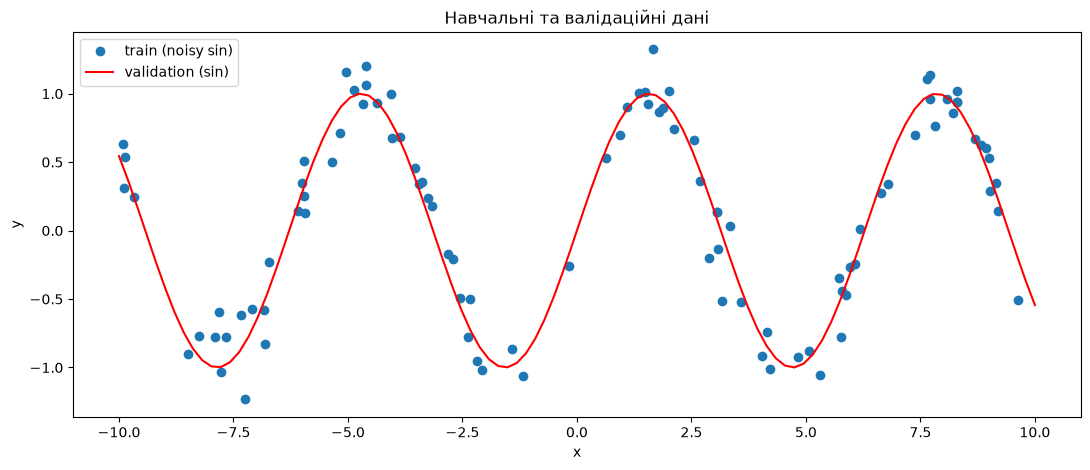

In [ ]:
torch.manual_seed(42)

x_train = torch.rand(100)
x_train = x_train * 20.0 - 10.0
y_train = torch.sin(x_train)

noise = torch.randn(y_train.shape) / 5.
y_train = y_train + noise

x_train.unsqueeze_(1)
y_train.unsqueeze_(1)

x_validation = torch.linspace(-10, 10, 100)
y_validation = torch.sin(x_validation.data)

x_validation.unsqueeze_(1)
y_validation.unsqueeze_(1)

print(x_train.shape, y_train.shape)
print(x_validation.shape, y_validation.shape)

plt.plot(x_train.numpy(), y_train.numpy(), 'o', label='train (noisy sin)')
plt.plot(x_validation.numpy(), y_validation.numpy(), '-', c='r', label='validation (sin)')
plt.title('Навчальні та валідаційні дані')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

Навчальні дані це 100 випадкових точок синуса з гаусовим шумом, а валідаційні це чистий синус у 100 рівномірно розподілених точках. Обидва набори мають форму `(100, 1)`.

SineNet(
  (fc1): Linear(in_features=1, out_features=50, bias=True)
  (act1): Tanh()
  (fc2): Linear(in_features=50, out_features=1, bias=True)
)


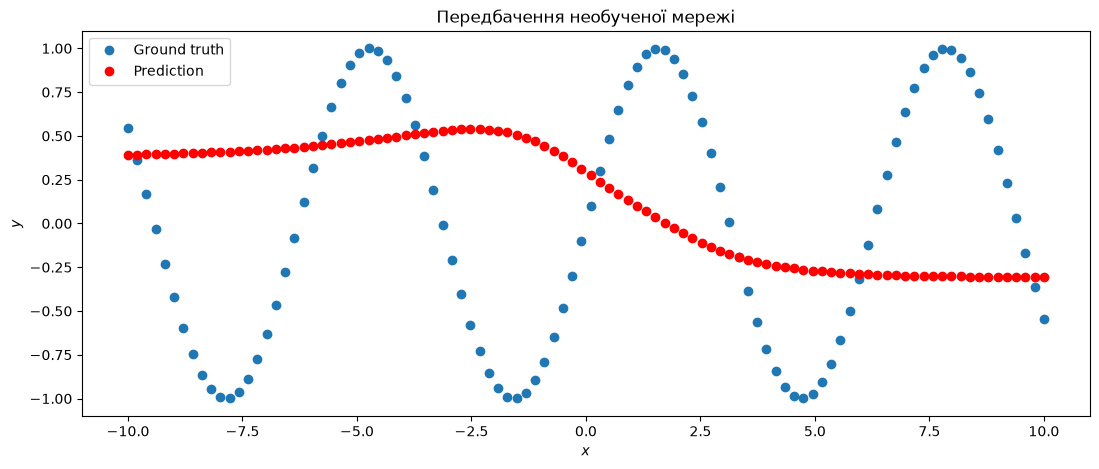

In [ ]:
class SineNet(torch.nn.Module):
    def __init__(self, n_hidden_neurons):
        super(SineNet, self).__init__()
        self.fc1 = torch.nn.Linear(1, n_hidden_neurons)
        self.act1 = torch.nn.Tanh()
        self.fc2 = torch.nn.Linear(n_hidden_neurons, 1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act1(x)
        x = self.fc2(x)
        return x

def predict(net, x, y):
    y_pred = net.forward(x)

    plt.plot(x.numpy(), y.numpy(), 'o', label='Ground truth')
    plt.plot(x.numpy(), y_pred.data.numpy(), 'o', c='r', label='Prediction')
    plt.legend(loc='upper left')
    plt.xlabel('$x$')
    plt.ylabel('$y$')

sine_net = SineNet(50)
print(sine_net)

predict(sine_net, x_validation, y_validation)
plt.title('Передбачення необученої мережі')
plt.show()

Мережа ініціалізована випадковими вагами, тому передбачення до навчання не схоже на синус.

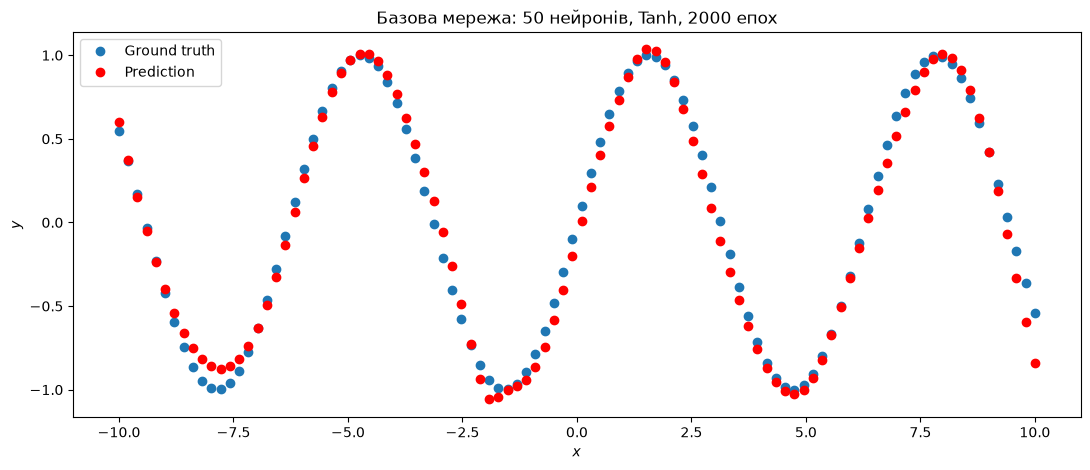

In [ ]:
def loss(pred, target):
    squares = (pred - target) ** 2
    return squares.mean()

optimizer = torch.optim.Adam(sine_net.parameters(), lr=0.01)

for epoch_index in range(2000):
    optimizer.zero_grad()

    y_pred = sine_net.forward(x_train)
    loss_val = loss(y_pred, y_train)

    loss_val.backward()

    optimizer.step()

predict(sine_net, x_validation, y_validation)
plt.title('Базова мережа: 50 нейронів, Tanh, 2000 епох')
plt.show()

Це базова конфігурація з теорії: 50 прихованих нейронів, активація Tanh, оптимізатор Adam зі швидкістю навчання 0.01, функція втрат MSE та 2000 епох. Далі змінюється по одному параметру.

## Допоміжні функції для експериментів

In [ ]:
class FlexibleSineNet(torch.nn.Module):
    def __init__(self, n_hidden_neurons, activation=torch.nn.Tanh, n_hidden_layers=1):
        super(FlexibleSineNet, self).__init__()
        layers = []
        in_features = 1
        for _ in range(n_hidden_layers):
            layers.append(torch.nn.Linear(in_features, n_hidden_neurons))
            layers.append(activation())
            in_features = n_hidden_neurons
        layers.append(torch.nn.Linear(in_features, 1))
        self.net = torch.nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def train_sine(net, epochs=2000, lr=0.01, loss_fn=loss, snapshots=()):
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    train_history = []
    val_history = []
    snapshot_predictions = {}

    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        y_pred = net.forward(x_train)
        loss_val = loss_fn(y_pred, y_train)
        loss_val.backward()
        optimizer.step()

        train_history.append(loss_val.item())
        with torch.no_grad():
            val_pred = net.forward(x_validation)
            val_history.append(loss(val_pred, y_validation).item())
            if epoch in snapshots:
                snapshot_predictions[epoch] = val_pred.numpy().copy()

    return train_history, val_history, snapshot_predictions

def final_prediction(net):
    with torch.no_grad():
        return net.forward(x_validation).numpy().copy()

def plot_grid(predictions, titles, rows, cols):
    fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 2.8 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, pred, title in zip(axes.flat, predictions, titles):
        ax.axis('on')
        ax.plot(x_validation.numpy(), y_validation.numpy(), '-', c='gray', label='sin(x)')
        ax.plot(x_validation.numpy(), pred, '-', c='r', label='prediction')
        ax.set_title(title, fontsize=10)
        ax.set_ylim(-2, 2)
    plt.tight_layout()
    plt.show()

curves = {}

# Завдання 1a. Кількість нейронів від 1 до 10

> a) Спробуйте змінити кількість нейронів (1,2,3,4,5,6,7,8,9,10 – проаналізуйте як змінюються передбачення)

          train MSE  validation MSE
нейронів                           
1            0.4369          0.4442
2            0.4185          0.4024
3            0.2542          0.2384
4            0.1670          0.1659
5            0.0412          0.0263
6            0.0342          0.0183
7            0.0361          0.0198
8            0.0948          0.0889
9            0.0700          0.0462
10           0.0311          0.0220


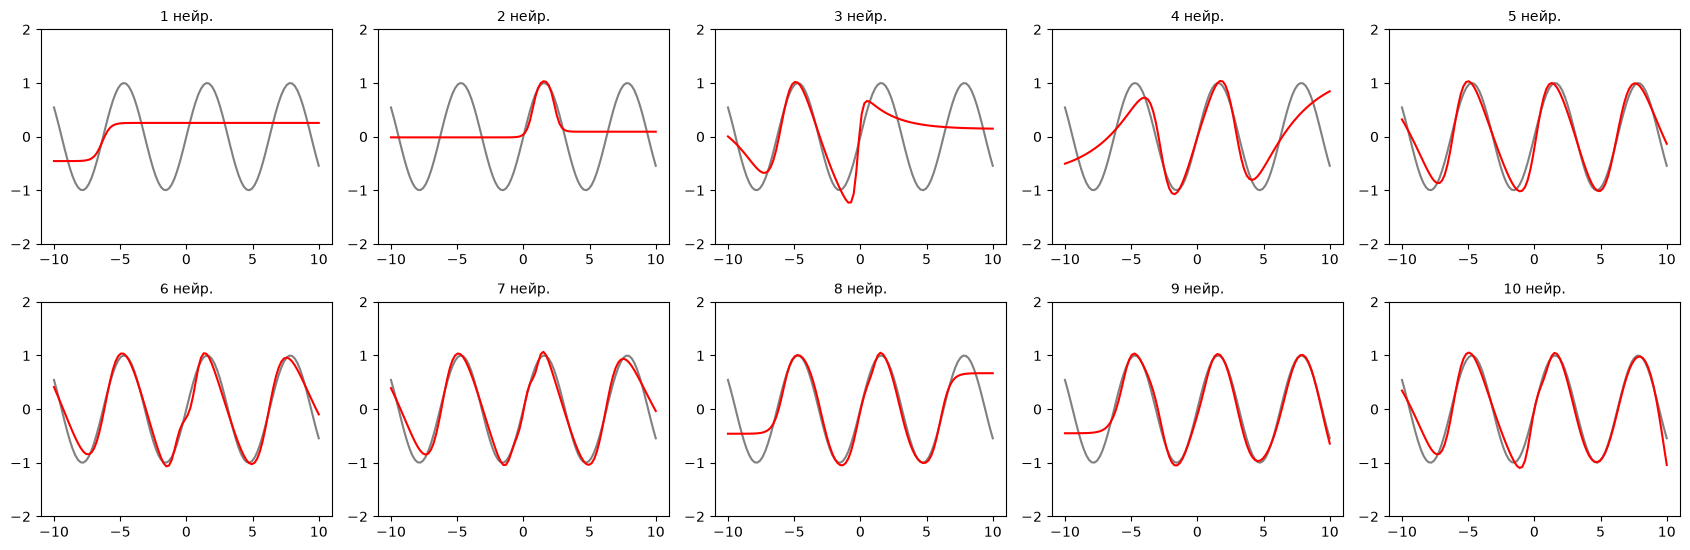

In [ ]:
rows = []
predictions = []
curves['a'] = {}

for n in range(1, 11):
    torch.manual_seed(42)
    net = FlexibleSineNet(n)
    train_h, val_h, _ = train_sine(net, epochs=2000)
    predictions.append(final_prediction(net))
    curves['a'][f'{n} нейр.'] = val_h
    rows.append({'нейронів': n, 'train MSE': train_h[-1], 'validation MSE': val_h[-1]})

result_a = pd.DataFrame(rows).set_index('нейронів')
print(result_a.round(4).to_string())

plot_grid(predictions, [f'{n} нейр.' for n in range(1, 11)], 2, 5)

# Завдання 1b. Кількість епох навчання

> b) Спробуйте змінити кількість епох навчання

      train MSE  validation MSE
епох                           
10       0.4567          0.4518
50       0.3175          0.2945
100      0.2047          0.2045
300      0.1127          0.1104
1000     0.0242          0.0049
2000     0.0225          0.0065
5000     0.0208          0.0146


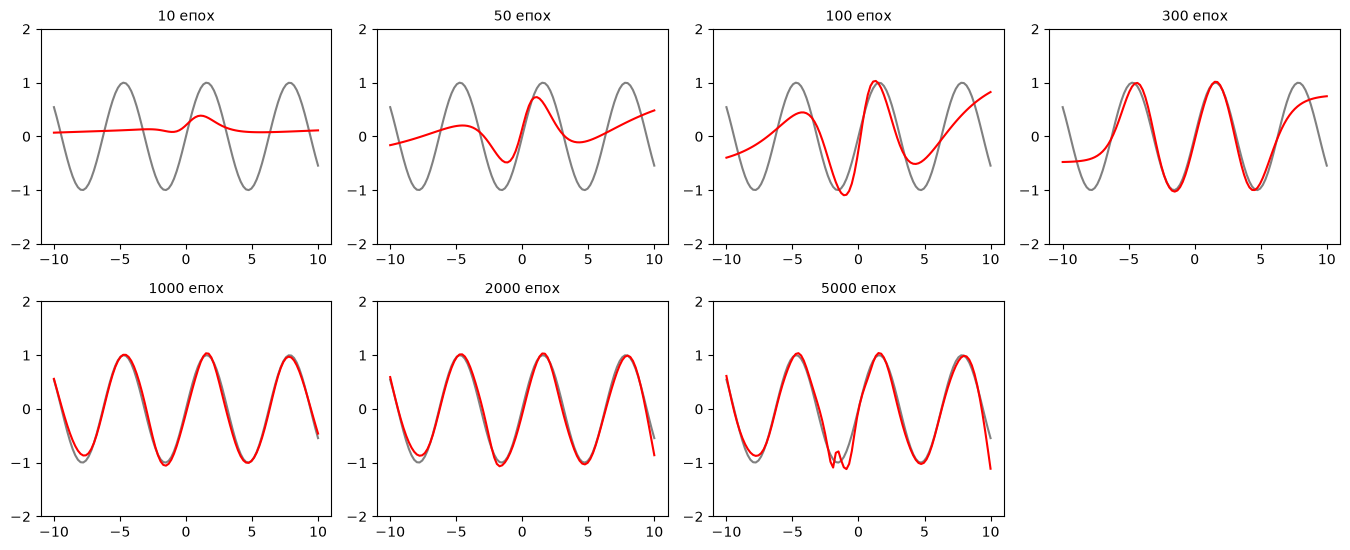

In [ ]:
checkpoints = [10, 50, 100, 300, 1000, 2000, 5000]

torch.manual_seed(42)
net = FlexibleSineNet(50)
train_h, val_h, snaps = train_sine(net, epochs=5000, snapshots=checkpoints)
curves['b'] = {'50 нейронів': val_h}

result_b = pd.DataFrame({
    'train MSE': [train_h[e - 1] for e in checkpoints],
    'validation MSE': [val_h[e - 1] for e in checkpoints],
}, index=pd.Index(checkpoints, name='епох'))
print(result_b.round(4).to_string())

plot_grid([snaps[e] for e in checkpoints], [f'{e} епох' for e in checkpoints], 2, 4)

# Завдання 1c. Функція активації

> c) Спробуйте змінити функцію активації

           train MSE  validation MSE
активація                           
Tanh          0.0225          0.0065
ReLU          0.1385          0.1083
Sigmoid       0.0238          0.0047
LeakyReLU     0.1369          0.1050
ELU           0.0616          0.0615


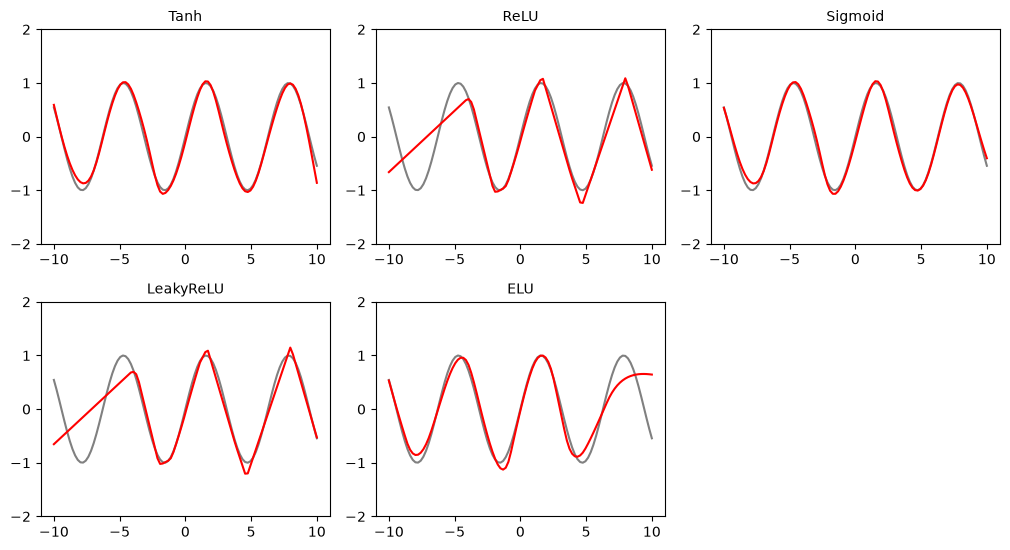

In [ ]:
activations = {
    'Tanh': torch.nn.Tanh,
    'ReLU': torch.nn.ReLU,
    'Sigmoid': torch.nn.Sigmoid,
    'LeakyReLU': torch.nn.LeakyReLU,
    'ELU': torch.nn.ELU,
}

rows = []
predictions = []
curves['c'] = {}

for name, act in activations.items():
    torch.manual_seed(42)
    net = FlexibleSineNet(50, activation=act)
    train_h, val_h, _ = train_sine(net, epochs=2000)
    predictions.append(final_prediction(net))
    curves['c'][name] = val_h
    rows.append({'активація': name, 'train MSE': train_h[-1], 'validation MSE': val_h[-1]})

result_c = pd.DataFrame(rows).set_index('активація')
print(result_c.round(4).to_string())

plot_grid(predictions, list(activations), 2, 3)

# Завдання 1d. Кількість шарів

> d) Спробуйте змінити (зменшити або додати додаткові шари)

                  train MSE  validation MSE
прихованих шарів                           
0                    0.4814          0.4777
1                    0.0225          0.0065
2                    0.0183          0.0199
3                    0.0189          0.0167


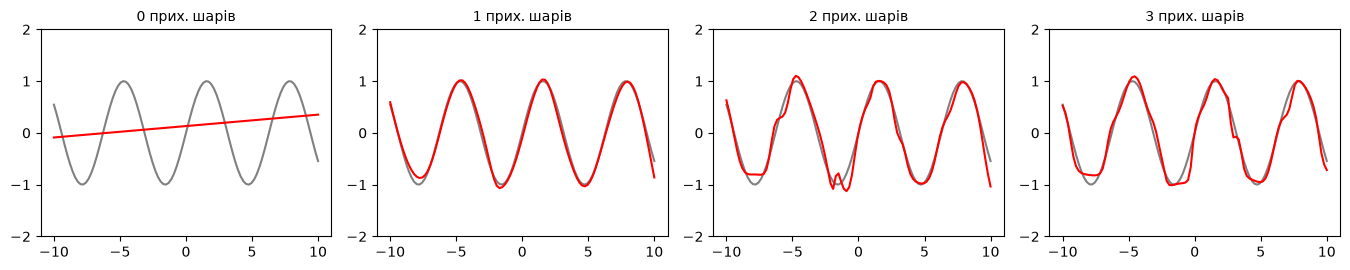

In [ ]:
rows = []
predictions = []
curves['d'] = {}

for layers in (0, 1, 2, 3):
    torch.manual_seed(42)
    net = FlexibleSineNet(50, n_hidden_layers=layers)
    train_h, val_h, _ = train_sine(net, epochs=2000)
    predictions.append(final_prediction(net))
    curves['d'][f'{layers} прих. шарів'] = val_h
    rows.append({'прихованих шарів': layers, 'train MSE': train_h[-1], 'validation MSE': val_h[-1]})

result_d = pd.DataFrame(rows).set_index('прихованих шарів')
print(result_d.round(4).to_string())

plot_grid(predictions, [f'{l} прих. шарів' for l in (0, 1, 2, 3)], 1, 4)

Нуль прихованих шарів означає, що лишається єдиний лінійний шар, тобто звичайна лінійна регресія. Це найпростіший спосіб «зменшити» мережу.

# Завдання 1e. Функція втрат

> e) Спробуйте змінити функцію втрат

                  train loss (власна)  validation MSE
функція втрат                                        
MSE                            0.0225          0.0065
L1 (MAE)                       0.2024          0.1197
Huber (SmoothL1)               0.0110          0.0056


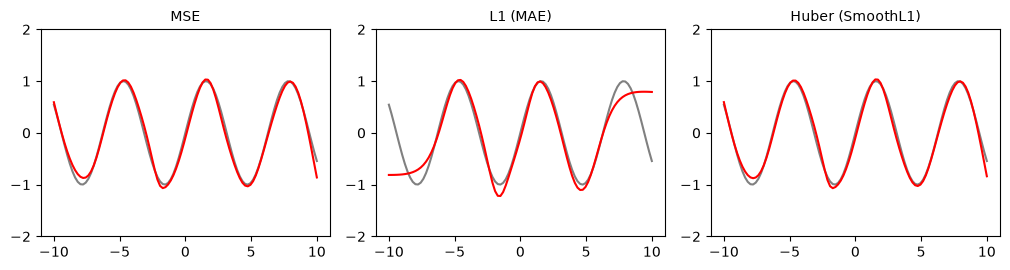

In [ ]:
loss_functions = {
    'MSE': torch.nn.MSELoss(),
    'L1 (MAE)': torch.nn.L1Loss(),
    'Huber (SmoothL1)': torch.nn.SmoothL1Loss(),
}

rows = []
predictions = []
curves['e'] = {}
train_curves_e = {}

for name, fn in loss_functions.items():
    torch.manual_seed(42)
    net = FlexibleSineNet(50)
    train_h, val_h, _ = train_sine(net, epochs=2000, loss_fn=fn)
    predictions.append(final_prediction(net))
    curves['e'][name] = val_h
    train_curves_e[name] = train_h
    rows.append({'функція втрат': name, 'train loss (власна)': train_h[-1], 'validation MSE': val_h[-1]})

result_e = pd.DataFrame(rows).set_index('функція втрат')
print(result_e.round(4).to_string())

plot_grid(predictions, list(loss_functions), 1, 3)

Значення втрат у різних функцій вимірюються в різних одиницях, тому для чесного порівняння на валідації скрізь рахується MSE.

# Завдання 1f. Графік втрат від номера епохи

> f) Запишіть значення функції втрат після кожної ітерації та виведіть графік залежності функції втрат від номера епохи.

Початкова втрата після 1-ї епохи: 0.61147540807724
Втрата після 2000-ї епохи: 0.022455422207713127


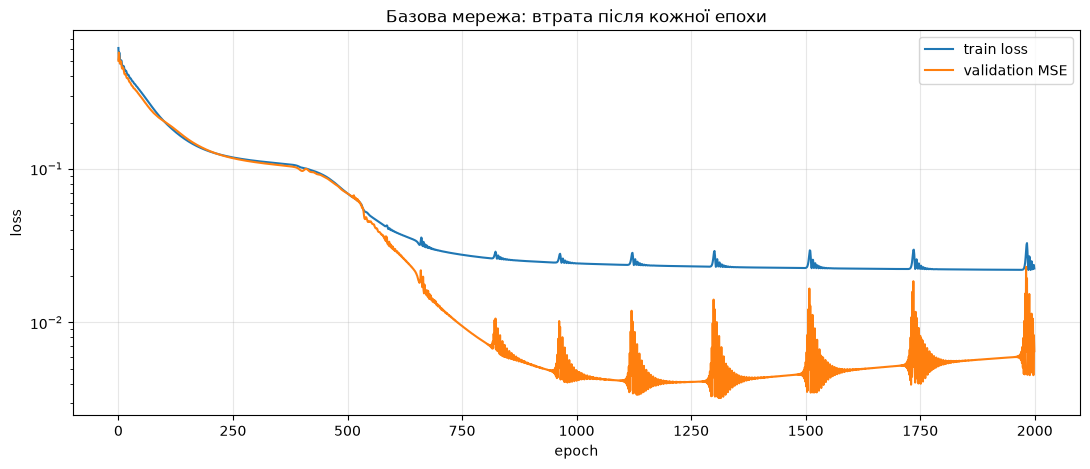

In [ ]:
torch.manual_seed(42)
base_net = FlexibleSineNet(50)
base_train, base_val, _ = train_sine(base_net, epochs=2000)

print("Початкова втрата після 1-ї епохи:", base_train[0])
print("Втрата після 2000-ї епохи:", base_train[-1])

plt.semilogy(base_train, label='train loss')
plt.semilogy(base_val, label='validation MSE')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('Базова мережа: втрата після кожної епохи')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

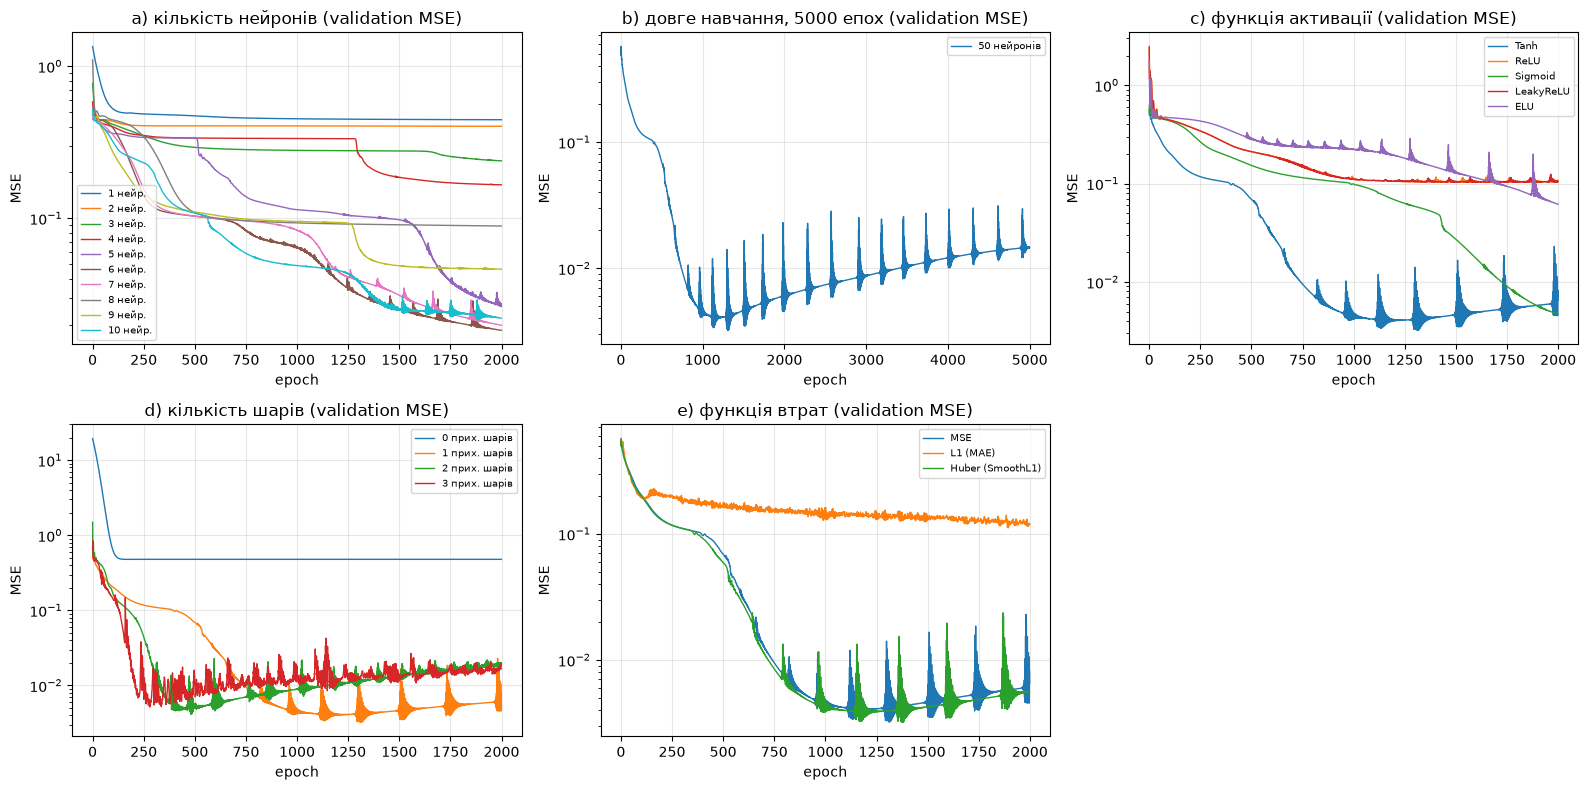

In [ ]:
titles = {
    'a': 'a) кількість нейронів',
    'b': 'b) довге навчання, 5000 епох',
    'c': 'c) функція активації',
    'd': 'd) кількість шарів',
    'e': 'e) функція втрат',
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for ax, (key, series) in zip(axes, curves.items()):
    for label, history in series.items():
        ax.semilogy(history, label=label, linewidth=1)
    ax.set_title(titles[key] + ' (validation MSE)')
    ax.set_xlabel('epoch')
    ax.set_ylabel('MSE')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

axes[5].axis('off')
plt.tight_layout()
plt.show()

# Завдання 1g. Пояснення отриманих результатів

> g) Поясніть отримані результати.

**Кількість нейронів (a).** На проміжку від -10 до 10 синус робить приблизно три періоди, і кожен нейрон з активацією Tanh дає мережі один «вигин». З одним і двома нейронами мережа не здатна відтворити кілька хвиль: валідаційна MSE становить 0.44 і 0.40, а це близько до дисперсії самого синуса (0.5), тобто прогноз майже не краще за пряму лінію. З 3 і 4 нейронами мережа вловлює лише частину хвиль (MSE 0.24 і 0.17), а з 5–7 нейронами синус відтворюється добре (MSE 0.018–0.026). Залежність не строго монотонна: у 8 і 9 нейронів MSE гірша (0.089 і 0.046), ніж у 6 чи 10 (0.018 і 0.022). Причина не в нестачі нейронів, а в тому, що за 2000 епох навчання з випадковою початковою ініціалізацією зупинилось у гіршому розв'язку. Тобто результат залежить не лише від розміру мережі, а й від початкових ваг.

**Кількість епох (b).** Після 10 епох мережа майже нічого не вивчила (MSE 0.45), після 100 епох MSE дорівнює 0.20, а після 300 епох 0.11. Найкращий результат досягається близько 1000 епох (MSE 0.0049). Далі втрата на тренувальних даних ще трохи зменшується (з 0.0242 до 0.0208 при переході від 1000 до 5000 епох), але валідаційна MSE зростає до 0.0146. Це перенавчання: мережа починає підлаштовуватись під шум у тренувальних точках, і через це відходить від справжнього синуса, на якому ми її перевіряємо.

**Функція активації (c).** Найкращі результати дають Sigmoid (MSE 0.0047) і Tanh (0.0065), бо це гладкі S-подібні функції, і з їхньої суми природно виходить гладка хвиля. ReLU і LeakyReLU дали помітно гірше (0.108 і 0.105): мережа з такими активаціями будує криву з прямолінійних відрізків і за 2000 епох не встигає добре наблизити синус. ELU знаходиться посередині (0.0615), бо поєднує лінійну частину та гладку частину.

**Кількість шарів (d).** Без прихованих шарів мережа перетворюється на лінійну регресію і не може описати синус (MSE 0.478, майже дисперсія самого синуса). Один прихований шар вирішує задачу (0.0065). Додавання другого і третього шарів не допомогло: втрата на навчанні трохи менша (0.0183 і 0.0189 проти 0.0225), а на валідації гірша (0.0199 і 0.0167). Для такої простої функції додаткові шари лише збільшують ризик підгонки під шум.

**Функція втрат (e).** MSE (0.0065) і Huber (0.0056) дають майже однаковий результат, а L1 помітно гірший (0.1197). Шум у даних гаусовий, а для нього MSE є природним вибором. У L1 величина градієнта не залежить від розміру помилки, тому біля мінімуму кроки Adam залишаються великими, і мережа за 2000 епох не встигає настільки точно підігнатись. Значення самих втрат у різних функцій непорівнянні, тому на валідації скрізь рахувалась MSE.

**Графіки втрат (f).** У всіх варіантів втрата різко падає в перші десятки і сотні епох, а потім виходить на плато. У базової мережі втрата на тренуванні дорівнює 0.61 після першої епохи і 0.0225 після 2000-ї. Дисперсія доданого шуму дорівнює 0.04 (стандартне відхилення 0.2), тому втрата на тренуванні нижче 0.04 означає, що мережа вже частково підлаштувалась під шум. Саме тому валідаційна MSE (на чистому синусі) мінімальна, коли мережа вже навчилась, але ще не почала повторювати шум.

# Завдання 2. Багатовимірна регресія: набір даних Energy efficiency

> Спробуйте вирішити задачу регресії на прикладі набору даних Енергоефективність з великої бібліотеки UCI (http://archive.ics.uci.edu/ml/datasets/Energy+efficiency). Це набір даних у якому описані наступні атрибути: X1 відносна компактність, X2 площа, X3 площа стіни, X4 площа стелі, X5 загальна висота, X6 орієнтація, X7 площа скління, X8 розподілена площа скління, y1 навантаження при обігріві, y2 навантаження при охолодженні.
>
> Маємо x1…x8 – характеристики приміщення на підставі яких буде проводитися аналіз, а y1 та y2 – значення навантаження, які треба спрогнозувати. При вирішенні завдання спробуйте вибрати чи всі ознаки Вам потрібні (якщо будете використовувати pandas – метод .corr()), архітектуру, кількість епох, спосіб ділення даних (зазвичай 60 (тренування) / 20 (валідація) / 20 (тест)), тощо.

## Допоміжні функції для регресії

In [ ]:
def split_60_20_20(X, y, seed=42):
    generator = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(X), generator=generator)
    n_train = int(0.6 * len(X))
    n_val = int(0.2 * len(X))
    train_idx = idx[:n_train]
    val_idx = idx[n_train:n_train + n_val]
    test_idx = idx[n_train + n_val:]
    return (X[train_idx], y[train_idx], X[val_idx], y[val_idx], X[test_idx], y[test_idx])

def build_mlp(in_dim, hidden, out_dim):
    layers = []
    previous = in_dim
    for size in hidden:
        layers.append(torch.nn.Linear(previous, size))
        layers.append(torch.nn.ReLU())
        previous = size
    layers.append(torch.nn.Linear(previous, out_dim))
    return torch.nn.Sequential(*layers)

def fit(model, X_tr, y_tr, X_va, y_va, epochs, lr=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()
    train_history = []
    val_history = []
    best_val = float('inf')
    best_epoch = 0
    best_state = None

    for epoch in range(1, epochs + 1):
        optimizer.zero_grad()
        loss_val = loss_fn(model(X_tr), y_tr)
        loss_val.backward()
        optimizer.step()

        with torch.no_grad():
            val_loss = loss_fn(model(X_va), y_va).item()

        train_history.append(loss_val.item())
        val_history.append(val_loss)

        if val_loss < best_val:
            best_val = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return train_history, val_history, best_epoch

def r2_score(y_true, y_pred):
    ss_res = ((y_true - y_pred) ** 2).sum(dim=0)
    ss_tot = ((y_true - y_true.mean(dim=0)) ** 2).sum(dim=0)
    return 1 - ss_res / ss_tot

def run_study(X, y, target_names, architectures, epochs):
    X_tr, y_tr, X_va, y_va, X_te, y_te = split_60_20_20(X, y)
    print("train / validation / test:", len(X_tr), len(X_va), len(X_te))

    x_mean, x_std = X_tr.mean(dim=0), X_tr.std(dim=0)
    y_mean, y_std = y_tr.mean(dim=0), y_tr.std(dim=0)

    def scale_x(a):
        return (a - x_mean) / x_std

    def scale_y(a):
        return (a - y_mean) / y_std

    X_tr_s, X_va_s, X_te_s = scale_x(X_tr), scale_x(X_va), scale_x(X_te)
    y_tr_s, y_va_s = scale_y(y_tr), scale_y(y_va)

    rows = []
    models = {}
    histories = {}

    for name, hidden in architectures.items():
        torch.manual_seed(42)
        model = build_mlp(X.shape[1], hidden, y.shape[1])
        train_h, val_h, best_epoch = fit(model, X_tr_s, y_tr_s, X_va_s, y_va_s, epochs)
        models[name] = model
        histories[name] = (train_h, val_h)
        rows.append({
            'архітектура': name,
            'параметрів': sum(p.numel() for p in model.parameters()),
            'найкраща епоха': best_epoch,
            'train MSE': train_h[best_epoch - 1],
            'validation MSE': val_h[best_epoch - 1],
        })

    table = pd.DataFrame(rows).set_index('архітектура')
    print(table.round(4).to_string())

    best_name = table['validation MSE'].idxmin()
    best_model = models[best_name]
    print("\nНайкраща архітектура за validation MSE:", best_name)

    plt.figure(figsize=(9, 5))
    for name, (train_h, val_h) in histories.items():
        plt.semilogy(val_h, label=f'{name} (validation)')
    plt.xlabel('epoch')
    plt.ylabel('MSE (нормовані цілі)')
    plt.title('Втрати на валідації за епохами')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    with torch.no_grad():
        pred_te = best_model(X_te_s) * y_std + y_mean

    rmse = ((pred_te - y_te) ** 2).mean(dim=0).sqrt()
    mae = (pred_te - y_te).abs().mean(dim=0)
    r2 = r2_score(y_te, pred_te)

    X_design = torch.cat([X_tr_s, torch.ones(len(X_tr_s), 1)], dim=1)
    linear_solution = torch.linalg.lstsq(X_design, y_tr_s).solution
    with torch.no_grad():
        pred_linear = torch.cat([X_te_s, torch.ones(len(X_te_s), 1)], dim=1) @ linear_solution * y_std + y_mean
    r2_linear = r2_score(y_te, pred_linear)
    rmse_linear = ((pred_linear - y_te) ** 2).mean(dim=0).sqrt()

    report = pd.DataFrame({
        'RMSE (нейромережа)': rmse.numpy(),
        'MAE (нейромережа)': mae.numpy(),
        'R2 (нейромережа)': r2.numpy(),
        'RMSE (лінійна регресія)': rmse_linear.numpy(),
        'R2 (лінійна регресія)': r2_linear.numpy(),
    }, index=target_names)
    print("\nРезультати на тестовій вибірці:")
    print(report.round(4).to_string())

    fig, axes = plt.subplots(1, y.shape[1], figsize=(6 * y.shape[1], 5), squeeze=False)
    for i, ax in enumerate(axes[0]):
        ax.scatter(y_te[:, i].numpy(), pred_te[:, i].numpy(), s=12)
        low = min(y_te[:, i].min().item(), pred_te[:, i].min().item())
        high = max(y_te[:, i].max().item(), pred_te[:, i].max().item())
        ax.plot([low, high], [low, high], 'r--')
        ax.set_xlabel('фактичне значення')
        ax.set_ylabel('прогноз')
        ax.set_title(f'{target_names[i]}: тест, R2 = {r2[i].item():.3f}')
    plt.tight_layout()
    plt.show()

    return table, report, best_name

## Завантаження та аналіз даних

In [ ]:
energy_url = 'https://archive.ics.uci.edu/static/public/242/energy+efficiency.zip'
archive = zipfile.ZipFile(io.BytesIO(urlopen(energy_url).read()))
energy = pd.read_excel(archive.open('ENB2012_data.xlsx'))

print(energy.shape)
print(energy.head())
print(energy.describe().round(2).to_string())
print("Пропущених значень:", energy.isna().sum().sum())

(768, 10)
     X1     X2     X3      X4   X5  X6   X7  X8     Y1     Y2
0  0.98  514.5  294.0  110.25  7.0   2  0.0   0  15.55  21.33
1  0.98  514.5  294.0  110.25  7.0   3  0.0   0  15.55  21.33
2  0.98  514.5  294.0  110.25  7.0   4  0.0   0  15.55  21.33
3  0.98  514.5  294.0  110.25  7.0   5  0.0   0  15.55  21.33
4  0.90  563.5  318.5  122.50  7.0   2  0.0   0  20.84  28.28
           X1      X2      X3      X4      X5      X6      X7      X8      Y1      Y2
count  768.00  768.00  768.00  768.00  768.00  768.00  768.00  768.00  768.00  768.00
mean     0.76  671.71  318.50  176.60    5.25    3.50    0.23    2.81   22.31   24.59
std      0.11   88.09   43.63   45.17    1.75    1.12    0.13    1.55   10.09    9.51
min      0.62  514.50  245.00  110.25    3.50    2.00    0.00    0.00    6.01   10.90
25%      0.68  606.38  294.00  140.88    3.50    2.75    0.10    1.75   12.99   15.62
50%      0.75  673.75  318.50  183.75    5.25    3.50    0.25    3.00   18.95   22.08
75%      0.83  7

Файл із UCI завантажується прямо за посиланням на архів набору даних.

      X1    X2    X3    X4    X5    X6    X7    X8    Y1    Y2
X1  1.00 -0.99 -0.20 -0.87  0.83  0.00 -0.00 -0.00  0.62  0.63
X2 -0.99  1.00  0.20  0.88 -0.86 -0.00  0.00  0.00 -0.66 -0.67
X3 -0.20  0.20  1.00 -0.29  0.28 -0.00 -0.00  0.00  0.46  0.43
X4 -0.87  0.88 -0.29  1.00 -0.97 -0.00 -0.00 -0.00 -0.86 -0.86
X5  0.83 -0.86  0.28 -0.97  1.00  0.00 -0.00 -0.00  0.89  0.90
X6  0.00 -0.00 -0.00 -0.00  0.00  1.00 -0.00 -0.00 -0.00  0.01
X7 -0.00  0.00 -0.00 -0.00 -0.00 -0.00  1.00  0.21  0.27  0.21
X8 -0.00  0.00  0.00 -0.00 -0.00 -0.00  0.21  1.00  0.09  0.05
Y1  0.62 -0.66  0.46 -0.86  0.89 -0.00  0.27  0.09  1.00  0.98
Y2  0.63 -0.67  0.43 -0.86  0.90  0.01  0.21  0.05  0.98  1.00


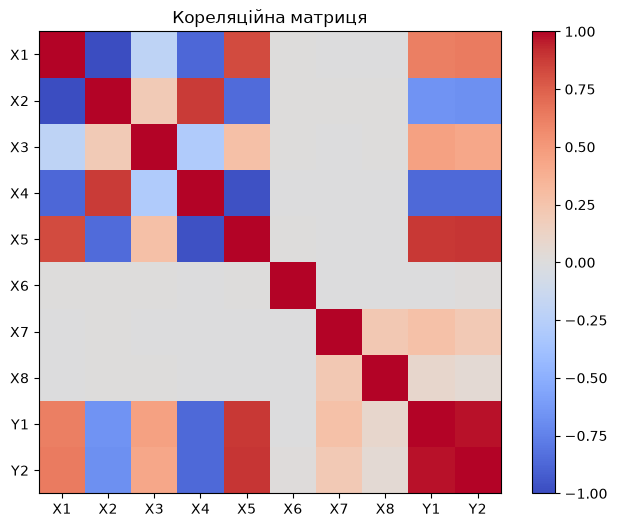

In [ ]:
correlations = energy.corr()
print(correlations.round(2).to_string())

plt.figure(figsize=(8, 6))
plt.imshow(correlations, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(correlations)), correlations.columns)
plt.yticks(range(len(correlations)), correlations.columns)
plt.title('Кореляційна матриця')
plt.show()

## Вибір ознак

In [ ]:
target_columns = ['Y1', 'Y2']
feature_columns = [c for c in energy.columns if c not in target_columns]

target_corr = energy.corr().loc[feature_columns, target_columns].abs()
print(target_corr.round(3).to_string())

selected_energy = [c for c in feature_columns if target_corr.loc[c].max() >= 0.1]
dropped_energy = [c for c in feature_columns if c not in selected_energy]

print("Залишаємо ознаки:", selected_energy)
print("Відкидаємо ознаки:", dropped_energy)

       Y1     Y2
X1  0.622  0.634
X2  0.658  0.673
X3  0.456  0.427
X4  0.862  0.863
X5  0.889  0.896
X6  0.003  0.014
X7  0.270  0.208
X8  0.087  0.051
Залишаємо ознаки: ['X1', 'X2', 'X3', 'X4', 'X5', 'X7']
Відкидаємо ознаки: ['X6', 'X8']


Ознаки, кореляція яких з обома цільовими змінними за модулем менша за 0.1, майже не несуть інформації для прогнозу, тому відкидаються.

## Навчання та порівняння архітектур

train / validation / test: 460 153 155


             параметрів  найкраща епоха  train MSE  validation MSE
архітектура                                                       
16                  146             500     0.0207          0.0152
32-16               786             490     0.0152          0.0133
64-32              2594             284     0.0183          0.0135
64-64-32           6754             208     0.0150          0.0135

Найкраща архітектура за validation MSE: 32-16


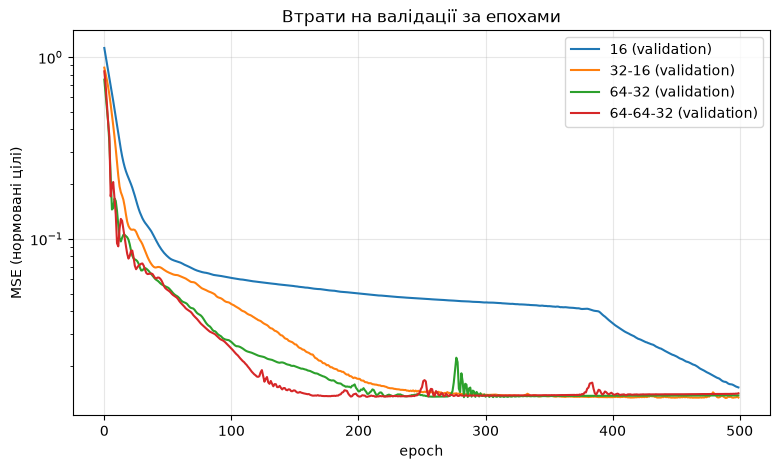


Результати на тестовій вибірці:
    RMSE (нейромережа)  MAE (нейромережа)  R2 (нейромережа)  RMSE (лінійна регресія)  R2 (лінійна регресія)
Y1              0.4968             0.3660            0.9974                   2.9252                 0.9116
Y2              1.6164             1.0786            0.9685                   3.0806                 0.8857


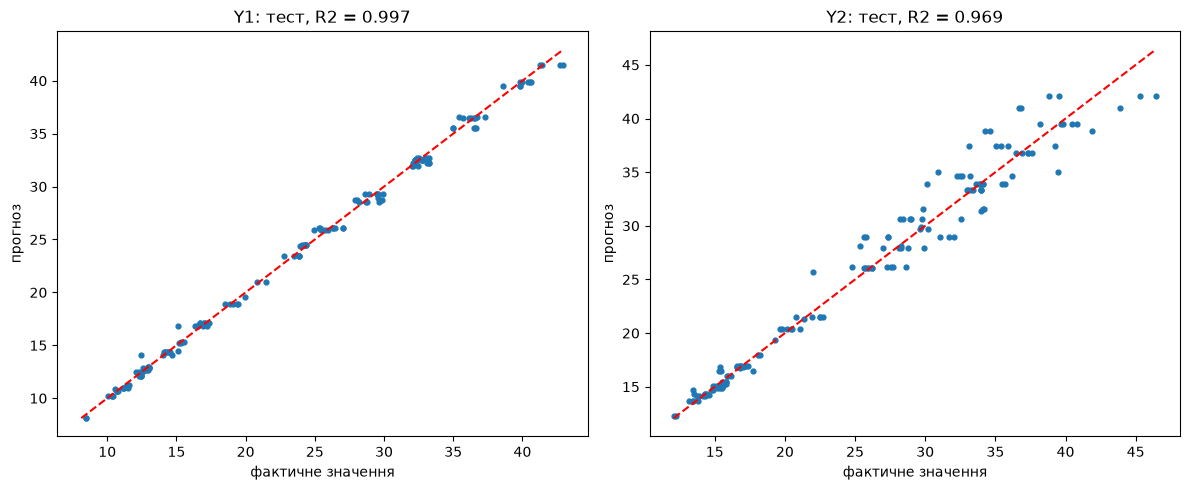

In [ ]:
X_energy = torch.tensor(energy[selected_energy].values, dtype=torch.float32)
y_energy = torch.tensor(energy[target_columns].values, dtype=torch.float32)

architectures_energy = {
    '16': (16,),
    '32-16': (32, 16),
    '64-32': (64, 32),
    '64-64-32': (64, 64, 32),
}

table_energy, report_energy, best_energy = run_study(
    X_energy, y_energy, target_columns, architectures_energy, epochs=500)

Дані діляться випадково у співвідношенні 60 / 20 / 20 на тренувальну, валідаційну й тестову вибірки. Ознаки та цілі нормуються за середнім і стандартним відхиленням тренувальної вибірки. Для кожної архітектури зберігаються ваги на епосі з найменшою втратою на валідації, а найкраща архітектура обирається за валідацією, не за тестом. Тестова вибірка використовується один раз для фінальної оцінки.

**Аналіз результатів.** За кореляцією відкинуто ознаки X6 (орієнтація, кореляція 0.00–0.01) і X8 (розподілена площа скління, 0.05–0.09), бо вони майже не пов'язані з навантаженням. Залишено X1–X5 і X7. Найсильніше на обидва навантаження впливають загальна висота X5 (0.89–0.90) та площа стелі X4 (-0.86); ознаки X1 і X2 між собою майже дублюють одна одну (кореляція -0.99).

Усі чотири архітектури показали близьку валідаційну MSE (0.0133–0.0152 у нормованих одиницях). Найменшу дала архітектура `32-16` (786 параметрів), тому її обрано. Простіша мережа з одним шаром на 16 нейронів лише трохи гірша, а більші мережі `64-32` і `64-64-32` покращення не дали, але вимагають більше параметрів.

На тестовій вибірці, яку мережа не бачила, обрана архітектура дала для навантаження при обігріві Y1 RMSE 0.50 (R² = 0.997), а для навантаження при охолодженні Y2 RMSE 1.62 (R² = 0.969). Для порівняння, звичайна лінійна регресія дає R² 0.912 і 0.886 та RMSE 2.93 і 3.08. Отже, нейромережа суттєво точніша за лінійну модель, бо залежність навантаження від параметрів приміщення нелінійна. Y2 прогнозується гірше, ніж Y1.

# Завдання 3. Набір даних «Діабет»

> Проаналізуйте аналогічно до другого завдання набір даних «Діабет» (https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html), який можна завантажити із бібліотеки sklearn:
>
> `from sklearn import datasets`
>
> `diabetes_X, diabetes_y = datasets.load_diabetes(return_X_y=True)`
>
> Набір даних про діабет складається з 10 фізіологічних змінних (вік, стать, вага, артеріальний тиск, тощо) виміряних на 442 пацієнтах та вказує на прогресування захворювання через рік (колонка таргету). Дані вже нормовані (мають середнє значення 0 та евклідову норму 1). Проаналізуйте дані, які поля та ознаки в нас є, кореляція між ознаками та таргетом, тощо. Натренуйте модель та отримайте передбачення.

In [ ]:
diabetes_X, diabetes_y = datasets.load_diabetes(return_X_y=True)
diabetes_names = datasets.load_diabetes().feature_names

diabetes = pd.DataFrame(diabetes_X, columns=diabetes_names)
diabetes['target'] = diabetes_y

print(diabetes.shape)
print(diabetes.head())
print(diabetes.describe().round(3).to_string())
print("Пропущених значень:", diabetes.isna().sum().sum())
print("Норма стовпців:", np.linalg.norm(diabetes_X, axis=0).round(2))

(442, 11)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
           age      sex      bmi       bp       s1       s2       s3       s4       s5       s6   target
count  442.000  442.000  442.000  442.000  442.000  442.000  442.000  442.000  442.000  442.000  442.000
mean    -0.000    0.000   -0.000   -0.000   -0.000    0.000   -0.000   -0.000

Усі десять ознак (`age`, `sex`, `bmi`, `bp` та шість показників крові `s1`–`s6`) уже нормовані: середнє дорівнює нулю, а евклідова норма кожного стовпця дорівнює одиниці. Таргет не нормований і вказує на прогресування захворювання через рік.

bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s3    -0.395
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043


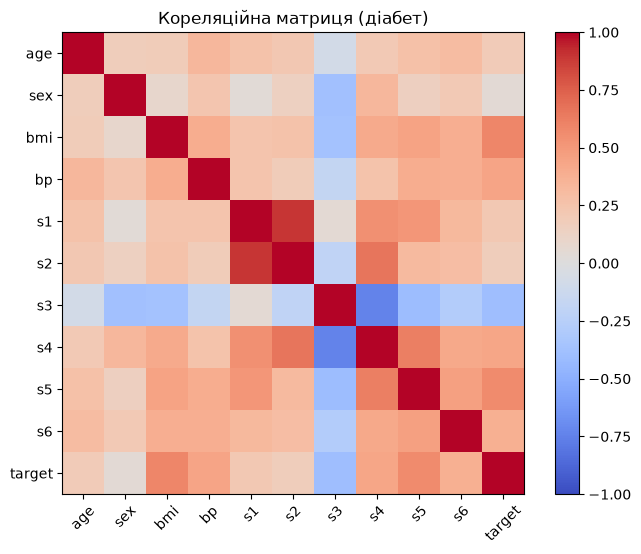

In [ ]:
diabetes_corr = diabetes.corr()
print(diabetes_corr['target'].drop('target').sort_values(key=abs, ascending=False).round(3).to_string())

plt.figure(figsize=(8, 6))
plt.imshow(diabetes_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(diabetes_corr)), diabetes_corr.columns, rotation=45)
plt.yticks(range(len(diabetes_corr)), diabetes_corr.columns)
plt.title('Кореляційна матриця (діабет)')
plt.show()

In [ ]:
feature_diabetes = list(diabetes_names)
corr_with_target = diabetes_corr.loc[feature_diabetes, 'target'].abs()

selected_diabetes = [c for c in feature_diabetes if corr_with_target[c] >= 0.1]
dropped_diabetes = [c for c in feature_diabetes if c not in selected_diabetes]

print("Залишаємо ознаки:", selected_diabetes)
print("Відкидаємо ознаки:", dropped_diabetes)

Залишаємо ознаки: ['age', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Відкидаємо ознаки: ['sex']


Вибір ознак виконується за тим самим правилом, що й у другому завданні: відкидаються ознаки з кореляцією з таргетом менше 0.1 за модулем.

train / validation / test: 265 88 89


             параметрів  найкраща епоха  train MSE  validation MSE
архітектура                                                       
8                    89              85     0.4761          0.5054
16                  177              34     0.4780          0.4911
32-16               865              21     0.4596          0.5076
64-32              2753              38     0.3486          0.4773

Найкраща архітектура за validation MSE: 64-32


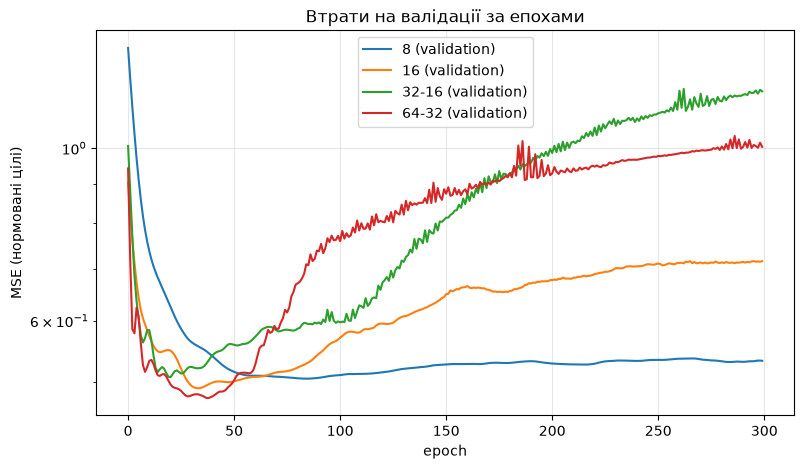


Результати на тестовій вибірці:
        RMSE (нейромережа)  MAE (нейромережа)  R2 (нейромережа)  RMSE (лінійна регресія)  R2 (лінійна регресія)
target           59.988899          48.189499            0.4402                58.680599                 0.4644


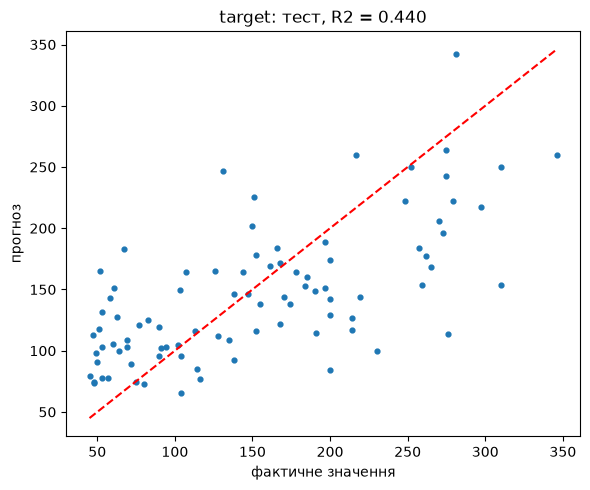

In [ ]:
X_diabetes = torch.tensor(diabetes[selected_diabetes].values, dtype=torch.float32)
y_diabetes = torch.tensor(diabetes[['target']].values, dtype=torch.float32)

architectures_diabetes = {
    '8': (8,),
    '16': (16,),
    '32-16': (32, 16),
    '64-32': (64, 32),
}

table_diabetes, report_diabetes, best_diabetes = run_study(
    X_diabetes, y_diabetes, ['target'], architectures_diabetes, epochs=300)

**Аналіз результатів.** Набір містить 442 пацієнти, 10 нормованих ознак і таргет із середнім значенням 152 та стандартним відхиленням 77. Найсильніше з таргетом пов'язані індекс маси тіла `bmi` (0.59), показник `s5` (0.57), артеріальний тиск `bp` (0.44), `s4` (0.43), `s3` (-0.40) та `s6` (0.38). Ознака `sex` має кореляцію лише 0.04, тому її відкинуто, решту дев'ять ознак залишено.

Найменшу валідаційну втрату (0.477 у нормованих одиницях) дала архітектура `64-32`, але різниця між архітектурами невелика (0.477–0.508). Найкраща епоха у всіх архітектур дуже рання (21–85 з 300), тобто мережа швидко починає перенавчатись, бо тренувальна вибірка складається лише з 265 прикладів.

На тестовій вибірці нейромережа дала RMSE 60.0 і MAE 48.2 при R² = 0.44. Лінійна регресія дала RMSE 58.7 і R² = 0.46, тобто нейромережа не перевершила лінійну модель. Помилка лише приблизно на чверть менша за стандартне відхилення таргету (77). Це означає, що в цих даних залежність майже лінійна, а значну частину розкиду таргету ознаки не пояснюють, тому для цього набору даних достатньо простої моделі.

# Висновки

У цьому практикумі ми навчились будувати та навчати нейронну мережу для задачі регресії в PyTorch: створювати клас мережі на основі `torch.nn.Module`, підбирати оптимізатор і функцію втрат, готувати тренувальну, валідаційну й тестову вибірки та аналізувати результати навчання. Метою завдання було засвоїти принцип роботи та способи побудови нейронної мережі для задачі регресії, і її досягнуто.

**Експерименти з мережею з теоретичної частини.** Мережа з одним прихованим шаром, Tanh, Adam зі швидкістю 0.01 і MSE відновлює синус добре вже з 5–7 нейронами та приблизно 1000 епохами (валідаційна MSE 0.005–0.026). Менше нейронів не дозволяє відтворити кілька періодів синуса, а надто довге навчання (5000 епох) призводить до перенавчання під шум. Гладкі активації Sigmoid і Tanh підходять краще за ReLU, додавання шарів не покращило результат, а втрата MSE (як і Huber) виявилась кращою за L1 для даних із гаусовим шумом. Результат також залежить від випадкової початкової ініціалізації ваг.

**Оптимальна мережа для другого завдання (Energy efficiency).** Відкинуто ознаки X6 і X8, а залишено шість ознак X1–X5 та X7. Оптимальною за валідацією виявилась мережа `32-16` на два приховані шари з активацією ReLU (786 параметрів), навчена 500 епох з вибором ваг на найкращій епосі. На тестових даних вона дала R² 0.997 для обігріву Y1 та 0.969 для охолодження Y2 (RMSE 0.50 і 1.62), що значно краще за лінійну регресію (R² 0.912 і 0.886).

**Оптимальна мережа для третього завдання («Діабет»).** Відкинуто ознаку `sex`, а решту дев'ять ознак залишено. Оптимальною за валідацією стала мережа `64-32`, але на тесті вона дала R² лише 0.44 (RMSE 60.0), що не краще за лінійну регресію (R² 0.46). Дані невеликі та зашумлені, залежність від ознак майже лінійна, мережа швидко перенавчається, тому для цього набору даних складна модель не дає переваги.

# Контрольні питання

**1. Які основні компоненти повинна містити програма для побудови нейронної мережі написана у PyTorch?**

Спочатку потрібні дані, підготовлені як тензори потрібної розмірності: тренувальний набір для навчання та валідаційний для перевірки. Далі описується сама мережа як клас, що успадковується від `torch.nn.Module`, у конструкторі `__init__` якого викликається батьківський конструктор через `super` і створюються шари (повнозв'язні `torch.nn.Linear` та функції активації, наприклад `Tanh`), а метод `forward` задає послідовне застосування цих шарів. Також потрібні оптимізатор із `torch.optim`, якому передаються параметри мережі `net.parameters()` та швидкість навчання, і функція втрат, наприклад MSE. Навчання виконується циклом по епохах: обнулення градієнтів `optimizer.zero_grad()`, обчислення передбачень через `forward`, обчислення втрат, `backward` і крок оптимізатора `optimizer.step()`. Після цього потрібна функція передбачення для перевірки результатів на валідаційних даних.

**2. Які доступні вбудовані оптимізатори реалізовані у PyTorch?**

Пакет `torch.optim` реалізує різні алгоритми оптимізації з єдиним загальним інтерфейсом, тому оптимізатор легко замінити іншим. З теорії відомі такі: SGD (стохастичний градієнтний спуск), у якого можна задати момент Нестерова та L2-регуляризацію, Adam, RProp та RMSProp. Усі вони приймають параметри, які потрібно навчати, і швидкість навчання, а кроки виконуються викликом `optimizer.step()`.